# Two-Way ANOVA: A Complete Guide for Data Science

## Objective

Two-Way ANOVA is used to examine the effects of two categorical independent variables on a continuous dependent variable.

In this notebook, we will investigate whether students' scores differ according to:

1. Teaching method: Traditional, Online, and Blended.
2. Study hours: Low and High.

We will test both main effects and the interaction effect between teaching method and study hours. We will also assess assumptions, calculate effect sizes, and interpret the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, levene
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

np.random.seed(42)

methods = ["Traditional", "Online", "Blended"]
hours = ["Low", "High"]

means = {
    ("Traditional", "Low"): 60,
    ("Traditional", "High"): 65,
    ("Online", "Low"): 66,
    ("Online", "High"): 69,
    ("Blended", "Low"): 68,
    ("Blended", "High"): 80
}

rows = []

for method in methods:
    for hour in hours:
        scores = np.random.normal(
            loc=means[(method, hour)],
            scale=5,
            size=30
        )

        for score in scores:
            rows.append((method, hour, score))

df = pd.DataFrame(
    rows,
    columns=["teaching_method", "study_hours", "score"]
)

df.head()

,teaching_method,study_hours,score
0,Traditional,Low,62.483571
1,Traditional,Low,59.308678
2,Traditional,Low,63.238443
3,Traditional,Low,67.615149
4,Traditional,Low,58.829233


In [2]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(180, 3)
<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   teaching_method  180 non-null    str    
 1   study_hours      180 non-null    str    
 2   score            180 non-null    float64
dtypes: float64(1), str(2)
memory usage: 4.3 KB
None
teaching_method    0
study_hours        0
score              0
dtype: int64


In [3]:
summary = (
    df.groupby(["teaching_method", "study_hours"])["score"]
      .agg(["count", "mean", "std"])
      .round(2)
)

summary

count   mean   std
teaching_method study_hours                    
Blended         High            30  81.39  4.74
                Low             30  67.53  5.12
Online          High            30  68.90  4.54
                Low             30  66.06  4.96
Traditional     High            30  64.39  4.66
                Low             30  59.06  4.50

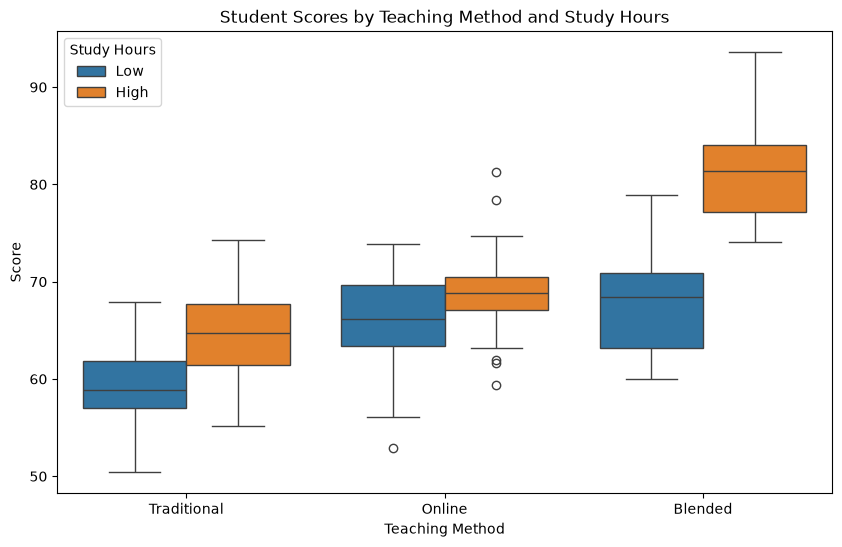

In [4]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="teaching_method",
    y="score",
    hue="study_hours"
)

plt.title("Student Scores by Teaching Method and Study Hours")
plt.xlabel("Teaching Method")
plt.ylabel("Score")
plt.legend(title="Study Hours")
plt.show()

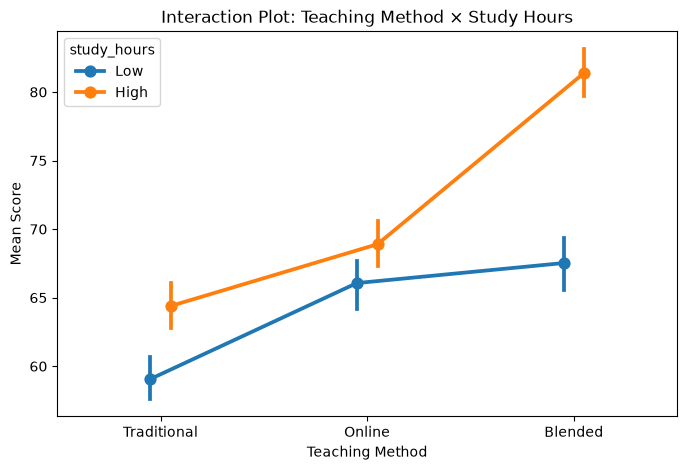

In [5]:
plt.figure(figsize=(8, 5))

sns.pointplot(
    data=df,
    x="teaching_method",
    y="score",
    hue="study_hours",
    errorbar=("ci", 95),
    dodge=0.1
)

plt.title("Interaction Plot: Teaching Method × Study Hours")
plt.xlabel("Teaching Method")
plt.ylabel("Mean Score")
plt.show()

In [6]:
model = ols(
    "score ~ C(teaching_method) * C(study_hours)",
    data=df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     73.42
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           4.75e-41
Time:                        22:23:17   Log-Likelihood:                -533.13
No. Observations:                 180   AIC:                             1078.
Df Residuals:                     174   BIC:                             1097.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

In [7]:
residuals = model.resid

stat, p_value = shapiro(residuals)

print("Shapiro-Wilk statistic:", round(stat, 4))
print("Shapiro p-value:", round(p_value, 4))

Shapiro-Wilk statistic: 0.9949
Shapiro p-value: 0.8007


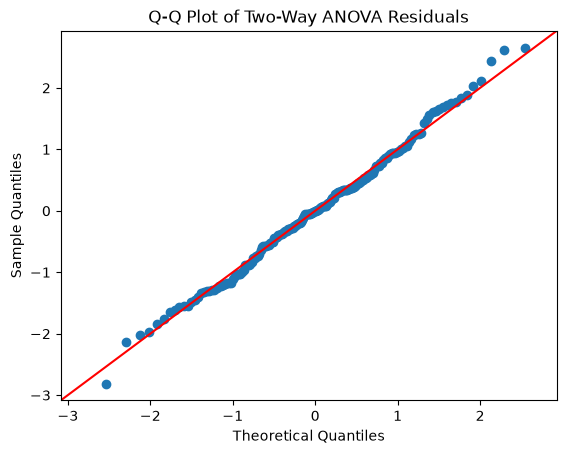

In [8]:
import statsmodels.api as sm

sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Two-Way ANOVA Residuals")
plt.show()

In [9]:
cell_groups = [
    group["score"].values
    for _, group in df.groupby(
        ["teaching_method", "study_hours"]
    )
]

stat, p_value = levene(
    *cell_groups,
    center="median"
)

print("Levene statistic:", round(stat, 4))
print("Levene p-value:", round(p_value, 4))

Levene statistic: 0.5499
Levene p-value: 0.7383


In [10]:
anova_table = anova_lm(model, typ=2)

anova_table

,sum_sq,df,F,PR(>F)
C(teaching_method),4878.720532,2.0,107.750410,3.577304e-31
C(study_hours),2428.359246,1.0,107.264477,6.938168e-20
C(teaching_method):C(study_hours),1004.184494,2.0,22.178210,2.632361e-09
Residual,3939.183960,174.0,NaN,NaN


In [ ]:
ss_error = anova_table.loc["Residual", "sum_sq"]

effects = [
    "C(teaching_method)",
    "C(study_hours)",
    "C(teaching_method):C(study_hours)"
]

for effect in effects:
    ss_effect = anova_table.loc[effect, "sum_sq"]

    partial_eta_sq = ss_effect / (ss_effect + ss_error)

    print(
        effect,
        "Partial eta-squared:",
        round(partial_eta_sq, 4)
    )

C(teaching_method) Partial eta-squared: 0.5533
C(study_hours) Partial eta-squared: 0.3814
C(teaching_method):C(study_hours) Partial eta-squared: 0.2031


In [12]:
cell_means = (
    df.groupby(["teaching_method", "study_hours"])["score"]
      .mean()
      .unstack()
      .round(2)
)

cell_means

study_hours,High,Low
teaching_method,,
Blended,81.39,67.53
Online,68.90,66.06
Traditional,64.39,59.06
